# Natural-Language-to-SQL Query Interface
**Jackfruit Problem – Mini-Project 8**

**Team**

| Name | SRN |
|---|---|
| Spoorthy M | PES1UG24AM280 |
| Aryaman D K | PES1UG24AM344 |
| Shristi Shukla | PES1UG24AM268 |
| Aditya Umashankar | PES1UG24AM335 |

Converts natural-language questions into SQLite queries over the **Spider** benchmark, validates each query by executing it, and explains the result in plain English.

- **Model:** `openai/gpt-oss-120b` via Groq (temperature 0)
- **Framework:** LangChain
- **Test set:** 100 Spider dev questions, stratified: 25 simple, 25 aggregation, 25 join, 25 nested

| Deliverable | Section |
|---|---|
| 1. Schema-aware SQL generator: zero-shot vs few-shot vs CoT with query planning | 4–7 |
| 2. Self-correction chain vs SQL agent with a database tool | 8, 10 |
| 3. Evaluation: execution accuracy, exact match, average correction iterations | 5, 11 |
| Interface: validation + natural-language explanation of results | 9 |

## 1. Setup: libraries, API key and model
The Groq API key is stored in Colab Secrets as `GROQ_API_KEY`.

In [4]:
!pip install -q langchain langchain-groq langchain-community groq

In [5]:
from google.colab import userdata
from groq import Groq

api_key = userdata.get('GROQ_API_KEY')
client = Groq(api_key=api_key)

models = client.models.list()
for m in models.data:
    print(m.id)

meta-llama/llama-prompt-guard-2-86m
openai/gpt-oss-safeguard-20b
openai/gpt-oss-120b
meta-llama/llama-prompt-guard-2-22m
canopylabs/orpheus-arabic-saudi
whisper-large-v3-turbo
whisper-large-v3
openai/gpt-oss-20b
canopylabs/orpheus-v1-english
qwen/qwen3.8-27b
allam-2-7b


In [6]:
from langchain_groq import ChatGroq

llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0,
    api_key=api_key
)

test_question = """
Table: students(id, name, age, city)
Write an SQL query to find the names of students older than 20 who live in Bengaluru.
Return only the SQL.
"""

response = llm.invoke(test_question)
print(response.content)

```sql
SELECT name
FROM students
WHERE age > 20
  AND city = 'Bengaluru';
```


## 2. Dataset: Spider and the 100-question test set
Questions are classified by their gold SQL (nested > join > aggregation > simple), duplicates removed, and 25 sampled per type with `random_state=42`.

In [7]:
!gdown 1403EGqzIDoHMdQF4c9Bkyl7dZLZ5Wt6J -O spider_data.zip
!unzip -q spider_data.zip
!ls spider_data

Downloading...
From (original): https://drive.google.com/uc?id=1403EGqzIDoHMdQF4c9Bkyl7dZLZ5Wt6J
From (redirected): https://drive.google.com/uc?id=1403EGqzIDoHMdQF4c9Bkyl7dZLZ5Wt6J&confirm=t&uuid=ea56a5ed-a198-415c-b5bf-12a9dc8e2ebd
To: /content/spider_data.zip
100% 206M/206M [00:05<00:00, 34.7MB/s]
database      README.txt     test_gold.sql     train_gold.sql
dev_gold.sql  tables.json    test.json	       train_others.json
dev.json      test_database  test_tables.json  train_spider.json


In [8]:
import json
import os

with open('spider_data/dev.json') as f:
    dev = json.load(f)

print("Number of questions:", len(dev))
print("Number of databases:", len(os.listdir('spider_data/database')))
print()
print("Example question:", dev[0]['question'])
print("Correct SQL:     ", dev[0]['query'])
print("Database:        ", dev[0]['db_id'])

Number of questions: 1034
Number of databases: 166

Example question: How many singers do we have?
Correct SQL:      SELECT count(*) FROM singer
Database:         concert_singer


In [9]:
import re
import pandas as pd

def get_category(sql):
    s = sql.lower()
    if s.count('select') > 1:
        return 'nested'
    if ' join ' in s:
        return 'join'
    if 'group by' in s or re.search(r'\b(count|sum|avg|max|min)\s*\(', s):
        return 'aggregation'
    return 'simple'

df_all = pd.DataFrame(dev)[['db_id', 'question', 'query']]
df_all['category'] = df_all['query'].apply(get_category)

df_all = df_all.drop_duplicates(subset='query')

print("All questions by type:")
print(df_all['category'].value_counts())

test_set = (
    df_all.groupby('category', group_keys=False)
    .sample(n=25, random_state=42)
    .reset_index(drop=True)
)
test_set.insert(0, 'qid', range(1, len(test_set) + 1))

print()
print("Our test set by type:")
print(test_set['category'].value_counts())

test_set.to_csv('test_set_100.csv', index=False)
test_set.head(10)

All questions by type:
category
join           180
aggregation    155
simple         135
nested          93
Name: count, dtype: int64

Our test set by type:
category
aggregation    25
join           25
nested         25
simple         25
Name: count, dtype: int64


,qid,db_id,question,query,category
0,1,battle_death,How many ships ended up being 'Captured'?,SELECT count(*) FROM ship WHERE disposition_of...,aggregation
1,2,network_1,Show me all grades that have at least 4 students.,SELECT grade FROM Highschooler GROUP BY grade ...,aggregation
2,3,flight_2,How many flights have destination ATO?,SELECT count(*) FROM FLIGHTS WHERE DestAirport...,aggregation
3,4,flight_2,How many airlines are from USA?,SELECT count(*) FROM AIRLINES WHERE Country =...,aggregation
4,5,world_1,How many people live in Gelderland district?,SELECT sum(Population) FROM city WHERE Distric...,aggregation
5,6,museum_visit,Find the average number of staff working for t...,SELECT avg(num_of_staff) FROM museum WHERE ope...,aggregation
6,7,tvshow,Which country has the most of TV Channels? Lis...,"SELECT Country , count(*) FROM TV_Channel GRO...",aggregation
7,8,dog_kennels,What is the average age of all the dogs?,SELECT avg(age) FROM Dogs,aggregation
8,9,singer,Show different citizenships and the maximum ne...,"SELECT Citizenship , max(Net_Worth_Millions) ...",aggregation
9,10,wta_1,find the number of distinct country codes of a...,SELECT count(DISTINCT country_code) FROM players,aggregation


## 3. Database helpers
`get_schema` gives the LLM the real `CREATE TABLE` statements (schema-aware generation), `clean_sql` strips markdown fences, `run_sql` executes a query and returns rows or the error message.

In [10]:
import sqlite3

def db_path(db_id):
    return f'spider_data/database/{db_id}/{db_id}.sqlite'

def get_schema(db_id):
    conn = sqlite3.connect(db_path(db_id))
    rows = conn.execute(
        "SELECT sql FROM sqlite_master WHERE type='table' AND sql IS NOT NULL"
    ).fetchall()
    conn.close()
    return "\n\n".join(r[0].strip() for r in rows)

def clean_sql(text):
    text = text.strip()
    blocks = re.findall(r"```(?:sql)?\s*(.*?)```", text, re.DOTALL | re.IGNORECASE)
    if blocks:
        text = blocks[-1]
    return text.strip().rstrip(';').strip()

def run_sql(db_id, sql):
    conn = sqlite3.connect(db_path(db_id))
    conn.text_factory = lambda b: b.decode(errors='ignore')
    try:
        rows = conn.execute(sql).fetchall()
        return rows, None
    except Exception as e:
        return None, str(e)
    finally:
        conn.close()

print("Helpers ready")

Helpers ready


In [11]:
row = test_set.iloc[0]

print("QUESTION:", row['question'])
print()
print("SCHEMA:")
print(get_schema(row['db_id']))
print()

result, error = run_sql(row['db_id'], row['query'])
print("CORRECT SQL:", row['query'])
print("RESULT:", result)
print("ERROR:", error)

QUESTION: How many ships ended up being 'Captured'?

SCHEMA:
CREATE TABLE "battle" (
"id" int,
"name" text,
"date" text,
"bulgarian_commander" text,
"latin_commander" text,
"result" text,
primary key("id")
)

CREATE TABLE "ship" (
"lost_in_battle" int,
"id" int,
"name" text,
"tonnage" text,
"ship_type" text,
"location" text,
"disposition_of_ship" text,
primary key("id"),
foreign key (`lost_in_battle`) references `battle`("id") 
)

CREATE TABLE "death" (
"caused_by_ship_id" int,
"id" int,
"note" text,
"killed" int,
"injured" int,
primary key("id"),
foreign key ("caused_by_ship_id") references `ship`("id") 
)

CORRECT SQL: SELECT count(*) FROM ship WHERE disposition_of_ship  =  'Captured'
RESULT: [(4,)]
ERROR: None


## 4. Deliverable 1: Schema-aware SQL generator
Three prompting styles:
- **Zero-shot:** schema + question only
- **Few-shot:** 4 solved examples on a *separate* employee/department database (avoids test-set leakage)
- **Chain-of-Thought with query planning:** a 6-step plan (tables, joins, filters, aggregation, nesting, output) before the final query

In [12]:
ZERO_SHOT = """You are an expert in SQLite.
Given the database schema below, write one SQLite query that answers the question.

Schema:
{schema}

Question: {question}

Return only the SQL query, with no explanation."""


FEW_SHOT = """You are an expert in SQLite.
Given a database schema, write one SQLite query that answers the question.

Here are some solved examples on a different database:

Example schema:
CREATE TABLE department (dept_id int primary key, name text, budget real)
CREATE TABLE employee (emp_id int primary key, name text, age int, salary real, dept_id int, foreign key (dept_id) references department(dept_id))

Q: How many employees are older than 30?
SQL: SELECT count(*) FROM employee WHERE age > 30

Q: Show each department name and the number of employees in it.
SQL: SELECT T2.name, count(*) FROM employee AS T1 JOIN department AS T2 ON T1.dept_id = T2.dept_id GROUP BY T2.name

Q: Find the names of departments that have no employees.
SQL: SELECT name FROM department WHERE dept_id NOT IN (SELECT dept_id FROM employee)

Q: List the names of employees whose salary is above the average salary.
SQL: SELECT name FROM employee WHERE salary > (SELECT avg(salary) FROM employee)

Now solve this one.

Schema:
{schema}

Question: {question}

Return only the SQL query, with no explanation."""


COT = """You are an expert in SQLite.
Given the database schema below, write one SQLite query that answers the question.

Schema:
{schema}

Question: {question}

Plan the query step by step before writing it:
1. Tables: which tables contain the needed information?
2. Joins: if more than one table is needed, which foreign keys connect them?
3. Filters: which WHERE conditions are needed?
4. Aggregation: is COUNT, SUM, AVG, MAX, MIN, GROUP BY or HAVING needed?
5. Nesting: is a subquery or UNION, INTERSECT or EXCEPT needed?
6. Output: which columns should be returned, and is ORDER BY or LIMIT needed?

After the plan, write the final query on a new line starting with FINAL SQL:"""

PROMPTS = {'zero_shot': ZERO_SHOT, 'few_shot': FEW_SHOT, 'cot': COT}
print("Prompts ready")

Prompts ready


In [13]:
def generate_sql(question, db_id, style):
    prompt = PROMPTS[style].format(schema=get_schema(db_id), question=question)
    response = llm.invoke(prompt)
    raw = response.content

    text = raw
    if 'FINAL SQL:' in text:
        text = text.split('FINAL SQL:')[-1]
    sql = clean_sql(text)

    tokens = response.usage_metadata['total_tokens'] if response.usage_metadata else 0
    return sql, raw, tokens

print("Generator ready")

Generator ready


### Pilot run (4 questions)
The pilot showed the model adding extra columns (`SELECT *`) and unrequested `ORDER BY` clauses, so the same two output rules were added to **all three** prompts before the full run.

In [ ]:
samples = test_set.groupby('category').head(1)

for _, row in samples.iterrows():
    print("=" * 80)
    print(f"[{row['category'].upper()}] {row['question']}")
    print("CORRECT  :", row['query'])
    for style in ['zero_shot', 'few_shot', 'cot']:
        sql, raw, tokens = generate_sql(row['question'], row['db_id'], style)
        print(f"{style:9}:", sql, f"  ({tokens} tokens)")

[AGGREGATION] How many ships ended up being 'Captured'?
CORRECT  : SELECT count(*) FROM ship WHERE disposition_of_ship  =  'Captured'
zero_shot: SELECT COUNT(*) AS captured_ships
FROM ship
WHERE disposition_of_ship = 'Captured'   (404 tokens)
few_shot : SELECT COUNT(*) FROM ship WHERE disposition_of_ship = 'Captured'   (604 tokens)
cot      : SELECT COUNT(*) AS captured_ships
FROM ship
WHERE disposition_of_ship = 'Captured'   (735 tokens)
[JOIN] Which continent has the most diverse languages?
CORRECT  : SELECT T1.Continent FROM country AS T1 JOIN countrylanguage AS T2 ON T1.Code  =  T2.CountryCode GROUP BY T1.Continent ORDER BY COUNT(*) DESC LIMIT 1
zero_shot: SELECT c.Continent
FROM country AS c
JOIN countrylanguage AS cl ON c.Code = cl.CountryCode
GROUP BY c.Continent
ORDER BY COUNT(DISTINCT cl.Language) DESC
LIMIT 1   (841 tokens)
few_shot : SELECT c.Continent
FROM country c
JOIN countrylanguage cl ON c.Code = cl.CountryCode
GROUP BY c.Continent
HAVING COUNT(DISTINCT cl.Language) = 

In [14]:
RULES = """Rules:
- Return only the columns the question asks for. Do not use SELECT * and do not add extra columns.
- Do not add ORDER BY or LIMIT unless the question asks for an order, or for a top or bottom result.

"""

ZERO_SHOT = ZERO_SHOT.replace("Question: {question}", RULES + "Question: {question}")
FEW_SHOT = FEW_SHOT.replace("Question: {question}", RULES + "Question: {question}")
COT = COT.replace("Question: {question}", RULES + "Question: {question}")

PROMPTS = {'zero_shot': ZERO_SHOT, 'few_shot': FEW_SHOT, 'cot': COT}

print(COT)

You are an expert in SQLite.
Given the database schema below, write one SQLite query that answers the question.

Schema:
{schema}

Rules:
- Return only the columns the question asks for. Do not use SELECT * and do not add extra columns.
- Do not add ORDER BY or LIMIT unless the question asks for an order, or for a top or bottom result.

Question: {question}

Plan the query step by step before writing it:
1. Tables: which tables contain the needed information?
2. Joins: if more than one table is needed, which foreign keys connect them?
3. Filters: which WHERE conditions are needed?
4. Aggregation: is COUNT, SUM, AVG, MAX, MIN, GROUP BY or HAVING needed?
5. Nesting: is a subquery or UNION, INTERSECT or EXCEPT needed?
6. Output: which columns should be returned, and is ORDER BY or LIMIT needed?

After the plan, write the final query on a new line starting with FINAL SQL:


## 5. Evaluation metrics
- **Execution accuracy:** predicted and gold SQL return the same rows (row order only checked when the gold query has `ORDER BY`).
- **Exact-match accuracy:** normalised SQL text is identical. This is stricter than Spider's official clause-level exact-set match.

The second cell checks the metrics on three known cases. `run_sql` is upgraded with a 10-second timeout.

In [15]:
import time

def run_sql(db_id, sql, timeout=10):
    conn = sqlite3.connect(db_path(db_id))
    conn.text_factory = lambda b: b.decode(errors='ignore')
    start = time.time()
    conn.set_progress_handler(lambda: 1 if time.time() - start > timeout else 0, 10000)
    try:
        rows = conn.execute(sql).fetchall()
        return rows, None
    except Exception as e:
        return None, str(e)
    finally:
        conn.close()


def normalize_sql(sql):
    s = sql.lower().strip().rstrip(';')
    s = s.replace('"', "'")
    s = re.sub(r'\s+', ' ', s)
    s = re.sub(r'\s*([(),=<>!*+\-/])\s*', r'\1', s)
    return s.strip()


def exact_match(pred_sql, gold_sql):
    return normalize_sql(pred_sql) == normalize_sql(gold_sql)


def normalize_value(v):
    if isinstance(v, float):
        if v.is_integer():
            return int(v)
        return round(v, 4)
    return v


def execution_match(pred_sql, gold_sql, db_id):
    gold_rows, gold_err = run_sql(db_id, gold_sql)
    pred_rows, pred_err = run_sql(db_id, pred_sql)
    if gold_err or pred_err:
        return False
    gold_rows = [tuple(normalize_value(v) for v in r) for r in gold_rows]
    pred_rows = [tuple(normalize_value(v) for v in r) for r in pred_rows]
    if 'order by' in gold_sql.lower():
        return pred_rows == gold_rows
    return sorted(map(repr, pred_rows)) == sorted(map(repr, gold_rows))

print("Metrics ready")

Metrics ready


In [ ]:
tests = [
    ("Same SQL as the correct one",
     "museum_visit",
     "SELECT name FROM museum WHERE Museum_ID NOT IN (SELECT museum_id FROM visit)",
     "SELECT name FROM museum WHERE Museum_ID NOT IN (SELECT museum_id FROM visit)"),
    ("Different SQL, same answer",
     "museum_visit",
     "SELECT Name FROM museum m WHERE NOT EXISTS (SELECT 1 FROM visit v WHERE v.Museum_ID = m.Museum_ID)",
     "SELECT name FROM museum WHERE Museum_ID NOT IN (SELECT museum_id FROM visit)"),
    ("Extra columns (SELECT *)",
     "world_1",
     "SELECT * FROM city WHERE Population BETWEEN 160000 AND 900000",
     "SELECT name FROM city WHERE Population BETWEEN 160000 AND 900000"),
]

for name, db, pred, gold in tests:
    em = exact_match(pred, gold)
    ex = execution_match(pred, gold, db)
    print(f"{name:30} | exact match: {em!s:5} | execution match: {ex}")

Same SQL as the correct one    | exact match: True  | execution match: True
Different SQL, same answer     | exact match: False | execution match: True
Extra columns (SELECT *)       | exact match: False | execution match: False


## 6. Deliverable 1 results: 100 questions × 3 prompting styles
Resumable: results are saved after every question to `results_generation.csv`.

In [ ]:
RESULTS_FILE = 'results_generation.csv'

if os.path.exists(RESULTS_FILE):
    results = pd.read_csv(RESULTS_FILE).to_dict('records')
else:
    results = []
done = {(r['qid'], r['style']) for r in results}
print("Already done:", len(done))


def call_with_retry(question, db_id, style, max_tries=6):
    for attempt in range(max_tries):
        try:
            return generate_sql(question, db_id, style)
        except Exception as e:
            msg = str(e).lower()
            if 'per day' in msg:
                raise
            if '429' in msg or 'rate' in msg:
                print("   rate limit, waiting 20 seconds...")
                time.sleep(20)
            else:
                raise
    raise RuntimeError("Too many rate-limit retries")


stopped = False
for style in ['zero_shot', 'few_shot', 'cot']:
    for _, row in test_set.iterrows():
        if (row['qid'], style) in done:
            continue

        start = time.time()
        try:
            sql, raw, tokens = call_with_retry(row['question'], row['db_id'], style)
        except Exception as e:
            print("STOPPED:", e)
            stopped = True
            break
        latency = round(time.time() - start, 2)

        _, sql_error = run_sql(row['db_id'], sql)
        ex = execution_match(sql, row['query'], row['db_id'])
        em = exact_match(sql, row['query'])

        results.append({
            'qid': row['qid'],
            'category': row['category'],
            'db_id': row['db_id'],
            'question': row['question'],
            'gold_sql': row['query'],
            'style': style,
            'pred_sql': sql,
            'raw_output': raw,
            'tokens': tokens,
            'latency_s': latency,
            'sql_error': sql_error,
            'exec_match': ex,
            'exact_match': em,
        })
        pd.DataFrame(results).to_csv(RESULTS_FILE, index=False)
        print(f"{style:9} q{row['qid']:<3} | exec: {ex!s:5} | exact: {em!s:5} | {tokens} tokens")

    if stopped:
        break

print()
print("Finished rows:", len(results), "of 300")

Already done: 285
cot       q86  | exec: True  | exact: False | 693 tokens
cot       q87  | exec: True  | exact: True  | 619 tokens
cot       q88  | exec: True  | exact: False | 941 tokens
cot       q89  | exec: True  | exact: True  | 704 tokens
cot       q90  | exec: True  | exact: True  | 634 tokens
cot       q91  | exec: False | exact: False | 681 tokens
cot       q92  | exec: True  | exact: True  | 699 tokens
cot       q93  | exec: True  | exact: False | 810 tokens
cot       q94  | exec: True  | exact: True  | 936 tokens
cot       q95  | exec: True  | exact: True  | 586 tokens
cot       q96  | exec: True  | exact: True  | 658 tokens
cot       q97  | exec: True  | exact: False | 801 tokens
cot       q98  | exec: True  | exact: False | 693 tokens
cot       q99  | exec: True  | exact: True  | 911 tokens
cot       q100 | exec: True  | exact: True  | 616 tokens

Finished rows: 300 of 300


OVERALL RESULTS BY PROMPTING STYLE (%)


,questions,execution_accuracy,exact_match_accuracy,avg_tokens,avg_latency_s,sql_errors
style,,,,,,
zero_shot,100,86.0,23.0,621.0,3.70,0
few_shot,100,85.0,33.0,833.0,4.47,0
cot,100,88.0,21.0,918.0,5.81,1


EXECUTION ACCURACY BY QUESTION TYPE (%)


style,zero_shot,few_shot,cot
category,,,
aggregation,100.0,100.0,100.0
join,72.0,72.0,84.0
nested,76.0,72.0,72.0
simple,96.0,96.0,96.0


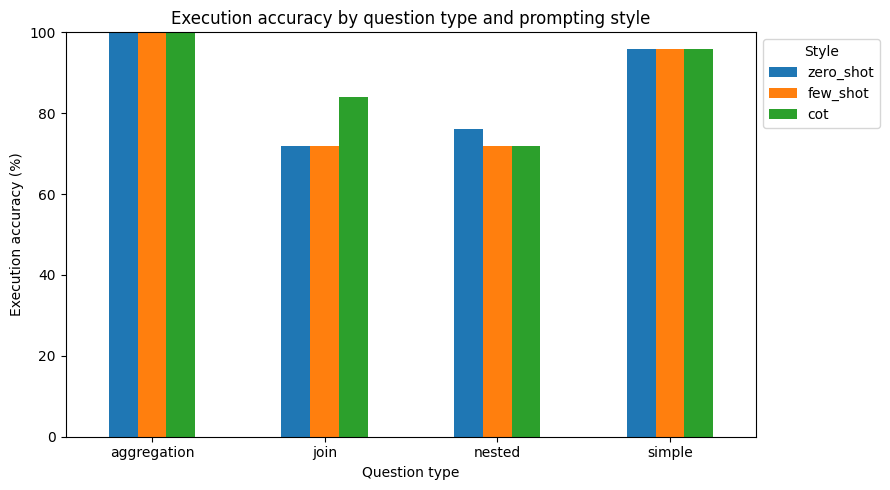

In [ ]:
import matplotlib.pyplot as plt

df = pd.read_csv('results_generation.csv')
style_order = ['zero_shot', 'few_shot', 'cot']

summary = df.groupby('style').agg(
    questions=('qid', 'count'),
    execution_accuracy=('exec_match', 'mean'),
    exact_match_accuracy=('exact_match', 'mean'),
    avg_tokens=('tokens', 'mean'),
    avg_latency_s=('latency_s', 'mean'),
    sql_errors=('sql_error', lambda s: s.notna().sum()),
).reindex(style_order)

summary['execution_accuracy'] = (summary['execution_accuracy'] * 100).round(1)
summary['exact_match_accuracy'] = (summary['exact_match_accuracy'] * 100).round(1)
summary['avg_tokens'] = summary['avg_tokens'].round(0)
summary['avg_latency_s'] = summary['avg_latency_s'].round(2)

print("OVERALL RESULTS BY PROMPTING STYLE (%)")
display(summary)

by_type = (df.pivot_table(index='category', columns='style',
                          values='exec_match', aggfunc='mean') * 100).round(1)
by_type = by_type[style_order]

print("EXECUTION ACCURACY BY QUESTION TYPE (%)")
display(by_type)

by_type.plot(kind='bar', figsize=(9, 5))
plt.title('Execution accuracy by question type and prompting style')
plt.ylabel('Execution accuracy (%)')
plt.xlabel('Question type')
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title='Style', loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.savefig('chart_generation_by_type.png', dpi=150)
plt.show()

## 7. Error analysis and metric fix
Most zero-shot "failures" were column-order differences, Spider label errors or ambiguous questions. The execution metric was then made **column-order tolerant** (as in Spider's official evaluation) and all saved answers were re-scored without new LLM calls. Re-run the Section 6 results cell afterwards for the final numbers.

In [ ]:
fails = df[(df['style'] == 'zero_shot') & (~df['exec_match'])]
print("Zero-shot failures:", len(fails))

for _, r in fails.iterrows():
    print("=" * 80)
    print(f"[{r['category']}] q{r['qid']}: {r['question']}")
    print("CORRECT  :", r['gold_sql'])
    print("PREDICTED:", r['pred_sql'])

Zero-shot failures: 21
[aggregation] q13: Find the number of matches happened in each year.
CORRECT  : SELECT count(*) ,  YEAR FROM matches GROUP BY YEAR
PREDICTED: SELECT year, COUNT(*) AS match_count
FROM matches
GROUP BY year
[aggregation] q18: How many times at most can a course enrollment result show in different transcripts? Also show the course enrollment id.
CORRECT  : SELECT count(*) ,  student_course_id FROM Transcript_Contents GROUP BY student_course_id ORDER BY count(*) DESC LIMIT 1
PREDICTED: WITH cnts AS (
  SELECT
    student_course_id,
    COUNT(DISTINCT transcript_id) AS transcript_count
  FROM Transcript_Contents
  GROUP BY student_course_id
)
SELECT
  student_course_id,
  transcript_count
FROM cnts
WHERE transcript_count = (SELECT MAX(transcript_count) FROM cnts)
[join] q27: Which address holds the most number of students currently? List the address id and all lines.
CORRECT  : SELECT T1.address_id ,  T1.line_1 ,  T1.line_2 FROM Addresses AS T1 JOIN Students AS T2 ON

In [16]:
from itertools import permutations

def rows_equal(pred_rows, gold_rows, order_matters):
    if len(pred_rows) != len(gold_rows):
        return False
    if len(gold_rows) == 0:
        return True

    n_cols = len(gold_rows[0])
    if any(len(r) != n_cols for r in pred_rows):
        return False

    def same(p, g):
        if order_matters:
            return p == g
        return sorted(map(repr, p)) == sorted(map(repr, g))

    if n_cols > 6:
        return same(pred_rows, gold_rows)

    for perm in permutations(range(n_cols)):
        permuted = [tuple(r[i] for i in perm) for r in pred_rows]
        if same(permuted, gold_rows):
            return True
    return False


def execution_match(pred_sql, gold_sql, db_id):
    gold_rows, gold_err = run_sql(db_id, gold_sql)
    pred_rows, pred_err = run_sql(db_id, pred_sql)
    if gold_err or pred_err:
        return False
    gold_rows = [tuple(normalize_value(v) for v in r) for r in gold_rows]
    pred_rows = [tuple(normalize_value(v) for v in r) for r in pred_rows]
    order_matters = 'order by' in gold_sql.lower()
    return rows_equal(pred_rows, gold_rows, order_matters)

print(execution_match("SELECT year, COUNT(*) FROM matches GROUP BY year",
                      "SELECT count(*), YEAR FROM matches GROUP BY YEAR",
                      "wta_1"))

True


In [ ]:
df = pd.read_csv(RESULTS_FILE)
df['exec_match'] = [
    execution_match(str(p), g, d)
    for p, g, d in zip(df['pred_sql'], df['gold_sql'], df['db_id'])
]
df.to_csv(RESULTS_FILE, index=False)
print("Re-scored", len(df), "rows")

Re-scored 285 rows


## 8. Deliverable 2a: Self-correction chain
Starting from each CoT query: **execute → show the LLM the result or error (row count + first rows) → LLM replies `CORRECT` or a fixed query**, up to 3 rounds. Reported: accuracy before/after, answers fixed/broken, and average correction iterations.

In [ ]:
CHECK_PROMPT = """You are an expert in SQLite. Review a query written by another assistant.

Schema:
{schema}

Question: {question}

SQL query:
{sql}

Execution result:
{feedback}

{rules}Does this query correctly and completely answer the question?
Check the tables, joins, filters, aggregation, nesting and the returned columns.
If it is correct, reply with exactly: CORRECT
If it is wrong, reply with the corrected query on a new line starting with FINAL SQL:"""


def describe_result(rows, error):
    if error:
        return f"ERROR: {error}"
    if len(rows) == 0:
        return "The query ran but returned 0 rows."
    preview = str(rows[:5])[:500]
    return f"The query returned {len(rows)} rows. First rows: {preview}"


def invoke_with_retry(prompt, max_tries=6):
    for attempt in range(max_tries):
        try:
            return llm.invoke(prompt)
        except Exception as e:
            msg = str(e).lower()
            if 'per day' in msg:
                raise
            if '429' in msg or 'rate' in msg:
                print("   rate limit, waiting 20 seconds...")
                time.sleep(20)
            else:
                raise
    raise RuntimeError("Too many rate-limit retries")


def self_correct(question, db_id, first_sql, max_rounds=3):
    sql = first_sql
    corrections = 0
    tokens = 0
    for _ in range(max_rounds):
        rows, err = run_sql(db_id, sql)
        prompt = CHECK_PROMPT.format(
            schema=get_schema(db_id),
            question=question,
            sql=sql,
            feedback=describe_result(rows, err),
            rules=RULES,
        )
        resp = invoke_with_retry(prompt)
        if resp.usage_metadata:
            tokens += resp.usage_metadata['total_tokens']
        text = resp.content.strip()

        if 'FINAL SQL:' in text:
            new_sql = clean_sql(text.split('FINAL SQL:')[-1])
            if normalize_sql(new_sql) == normalize_sql(sql):
                break
            sql = new_sql
            corrections += 1
        else:
            break
    return sql, corrections, tokens

print("Self-correction ready")

Self-correction ready


In [ ]:
SC_FILE = 'results_selfcorrect.csv'

gen = pd.read_csv(RESULTS_FILE)
cot_rows = gen[gen['style'] == 'cot'].sort_values('qid')

if os.path.exists(SC_FILE):
    sc_results = pd.read_csv(SC_FILE).to_dict('records')
else:
    sc_results = []
sc_done = {r['qid'] for r in sc_results}
print("Already done:", len(sc_done))

for _, row in cot_rows.iterrows():
    if row['qid'] in sc_done:
        continue

    start = time.time()
    try:
        final_sql, corrections, tokens = self_correct(row['question'], row['db_id'], str(row['pred_sql']))
    except Exception as e:
        print("STOPPED:", e)
        break
    latency = round(time.time() - start, 2)

    _, final_error = run_sql(row['db_id'], final_sql)
    ex = execution_match(final_sql, row['gold_sql'], row['db_id'])

    sc_results.append({
        'qid': row['qid'],
        'category': row['category'],
        'db_id': row['db_id'],
        'question': row['question'],
        'gold_sql': row['gold_sql'],
        'initial_sql': row['pred_sql'],
        'initial_exec': row['exec_match'],
        'final_sql': final_sql,
        'corrections': corrections,
        'check_tokens': tokens,
        'latency_s': latency,
        'final_error': final_error,
        'exec_match': ex,
        'exact_match': exact_match(final_sql, row['gold_sql']),
    })
    pd.DataFrame(sc_results).to_csv(SC_FILE, index=False)

    change = ""
    if row['exec_match'] and not ex:
        change = "  <-- BROKEN"
    elif not row['exec_match'] and ex:
        change = "  <-- FIXED"
    print(f"q{row['qid']:<3} | before: {row['exec_match']!s:5} | after: {ex!s:5} | corrections: {corrections} | {tokens} tokens{change}")

print()
print("Finished:", len(sc_results), "of 100")

Already done: 93
q94  | before: True  | after: True  | corrections: 0 | 777 tokens
q95  | before: True  | after: True  | corrections: 0 | 454 tokens
q96  | before: True  | after: True  | corrections: 0 | 581 tokens
q97  | before: True  | after: True  | corrections: 0 | 641 tokens
q98  | before: True  | after: True  | corrections: 0 | 542 tokens
q99  | before: True  | after: True  | corrections: 0 | 755 tokens
q100 | before: True  | after: True  | corrections: 0 | 507 tokens

Finished: 100 of 100


In [ ]:
sc = pd.read_csv(SC_FILE)

before = sc['initial_exec'].mean() * 100
after = sc['exec_match'].mean() * 100
fixed = ((~sc['initial_exec']) & sc['exec_match']).sum()
broken = (sc['initial_exec'] & ~sc['exec_match']).sum()

print("SELF-CORRECTION RESULTS on", len(sc), "questions")
print(f"Execution accuracy before : {before:.1f}%")
print(f"Execution accuracy after  : {after:.1f}%")
print(f"Answers fixed             : {fixed}")
print(f"Answers broken            : {broken}")
print(f"Average correction iterations       : {sc['corrections'].mean():.2f}")
print(f"Questions with at least 1 correction: {(sc['corrections'] > 0).sum()}")
print(f"Average extra tokens per question   : {sc['check_tokens'].mean():.0f}")
print()

print("Number of corrections per question:")
print(sc['corrections'].value_counts().sort_index())
print()

by_type = sc.groupby('category')[['initial_exec', 'exec_match']].mean() * 100
by_type.columns = ['before_%', 'after_%']
print("By question type:")
display(by_type.round(1))

changed = sc[sc['corrections'] > 0]
for _, r in changed.iterrows():
    print("=" * 80)
    print(f"[{r['category']}] q{r['qid']}: {r['question']}")
    print(f"before: {r['initial_exec']}  ->  after: {r['exec_match']}   ({r['corrections']} corrections)")
    print("INITIAL:", r['initial_sql'])
    print("FINAL  :", r['final_sql'])
    print("CORRECT:", r['gold_sql'])

SELF-CORRECTION RESULTS on 100 questions
Execution accuracy before : 88.0%
Execution accuracy after  : 86.0%
Answers fixed             : 0
Answers broken            : 2
Average correction iterations       : 0.05
Questions with at least 1 correction: 4
Average extra tokens per question   : 800

Number of corrections per question:
corrections
0    96
1     3
2     1
Name: count, dtype: int64

By question type:


,before_%,after_%
category,,
aggregation,100.0,100.0
join,84.0,76.0
nested,72.0,72.0
simple,96.0,96.0


[join] q39: Find the city with the largest population that uses English.
before: True  ->  after: False   (1 corrections)
INITIAL: SELECT city.Name, city.Population
FROM city
JOIN countrylanguage
  ON city.CountryCode = countrylanguage.CountryCode
WHERE countrylanguage.Language = 'English'
ORDER BY city.Population DESC
LIMIT 1
FINAL  : SELECT city.Name
FROM city
JOIN countrylanguage
  ON city.CountryCode = countrylanguage.CountryCode
WHERE countrylanguage.Language = 'English'
ORDER BY city.Population DESC
LIMIT 1
CORRECT: SELECT T1.Name ,  T1.Population FROM city AS T1 JOIN countrylanguage AS T2 ON T1.CountryCode  =  T2.CountryCode WHERE T2.Language  =  "English" ORDER BY T1.Population DESC LIMIT 1
[join] q41: Show the names of all of the high schooler Kyle's friends.
before: True  ->  after: False   (1 corrections)
INITIAL: SELECT f.name
FROM Highschooler AS k
JOIN Friend AS fr ON k.ID = fr.student_id
JOIN Highschooler AS f ON fr.friend_id = f.ID
WHERE k.name = 'Kyle'
FINAL  : SELECT 

## 9. Demo interface
Gradio app: **question → CoT SQL → validation by execution (self-correction if it errors) → result table → plain-English answer**. `share=True` prints a public link.

In [ ]:
!pip install -q gradio

In [ ]:
import gradio as gr

EXPLAIN_PROMPT = """A user asked a question about a database. An SQL query was run to answer it.

Question: {question}

SQL query:
{sql}

Result ({n_rows} rows, showing up to 20):
{rows}

Answer the user's question in 1 to 3 plain English sentences, using the result.
Do not mention SQL or the query. If the result is empty, say that no matching records were found."""


def run_sql_table(db_id, sql):
    conn = sqlite3.connect(db_path(db_id))
    conn.text_factory = lambda b: b.decode(errors='ignore')
    try:
        cur = conn.execute(sql)
        cols = [d[0] for d in cur.description] if cur.description else []
        rows = cur.fetchmany(200)
        return pd.DataFrame(rows, columns=cols), None
    except Exception as e:
        return None, str(e)
    finally:
        conn.close()


def schema_summary(db_id):
    conn = sqlite3.connect(db_path(db_id))
    tables = [r[0] for r in conn.execute("SELECT name FROM sqlite_master WHERE type='table'")]
    lines = []
    for t in tables:
        cols = [c[1] for c in conn.execute(f'PRAGMA table_info("{t}")')]
        lines.append(f"**{t}**: {', '.join(cols)}")
    conn.close()
    return "\n\n".join(lines)


def ask(db_id, question):
    if not question.strip():
        return "", "Please type a question.", None, ""
    try:
        sql, raw, _ = generate_sql(question, db_id, 'cot')
        table, error = run_sql_table(db_id, sql)

        corrections = 0
        if error:
            sql, corrections, _ = self_correct(question, db_id, sql)
            table, error = run_sql_table(db_id, sql)

        if error:
            return sql, f"✗ Invalid query: {error}", None, "Sorry, I could not produce a working query for this question."

        status = f"✓ Valid: the query ran successfully and returned {len(table)} row(s)."
        if corrections:
            status += f" Fixed after {corrections} correction(s)."

        resp = invoke_with_retry(EXPLAIN_PROMPT.format(
            question=question,
            sql=sql,
            n_rows=len(table),
            rows=table.head(20).to_string(index=False),
        ))
        return sql, status, table, resp.content.strip()
    except Exception as e:
        return "", f"Error: {e}", None, ""


db_list = sorted(set(d['db_id'] for d in dev))
default_db = 'concert_singer' if 'concert_singer' in db_list else db_list[0]

with gr.Blocks(title="NL2SQL Assistant") as demo:
    gr.Markdown("# Natural-Language-to-SQL Assistant\nPick a database and ask a question in plain English.")
    with gr.Row():
        db_input = gr.Dropdown(db_list, value=default_db, label="Database")
        q_input = gr.Textbox(label="Your question", placeholder="e.g. Which singer is the oldest?")
    with gr.Accordion("Tables in this database", open=False):
        schema_box = gr.Markdown(schema_summary(default_db))
    btn = gr.Button("Ask", variant="primary")
    sql_out = gr.Code(label="Generated SQL", language="sql")
    status_out = gr.Textbox(label="Validation")
    table_out = gr.Dataframe(label="Result")
    answer_out = gr.Textbox(label="Answer in plain English")

    db_input.change(schema_summary, db_input, schema_box)
    btn.click(ask, [db_input, q_input], [sql_out, status_out, table_out, answer_out])

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c65337b193803dc86c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 10. Deliverable 2b: LangChain SQL agent with database tools
The agent chooses its own tools in a ReAct-style loop: `sql_db_list_tables`, `sql_db_schema`, `sql_db_query`, and retries when a query fails. A 20-step recursion limit stops endless loops.

Some Spider tables store numbers in date-typed columns, which crashes the schema tool's sample-row reader (`fromisoformat`). `run_agent` falls back to a schema without sample rows in that case.

The second cell shows one full agent trace (tested on `gpt-oss-20b`); the third runs all 100 questions with `gpt-oss-120b`.

In [17]:
from langchain.agents import create_agent
from langchain_community.utilities import SQLDatabase
from langchain_community.agent_toolkits import SQLDatabaseToolkit

AGENT_PROMPT = """You are an agent that answers questions about a SQLite database using tools.
1. Look at the tables in the database.
2. Look at the schema of the relevant tables.
3. Write a SQLite query and run it with the query tool.
4. If the query fails or the result looks wrong, fix it and run it again.
Never change the database (no INSERT, UPDATE, DELETE or DROP).

""" + RULES + """When you are finished, reply with the final query on a new line starting with FINAL SQL:"""


def run_agent_once(question, db_id, model, sample_rows):
    db = SQLDatabase.from_uri(f"sqlite:///{db_path(db_id)}", sample_rows_in_table_info=sample_rows)
    toolkit = SQLDatabaseToolkit(db=db, llm=model)
    tools = [t for t in toolkit.get_tools() if t.name != 'sql_db_query_checker']
    agent = create_agent(model, tools, system_prompt=AGENT_PROMPT)

    out = agent.invoke(
        {"messages": [{"role": "user", "content": question}]},
        config={"recursion_limit": 20},
    )
    messages = out["messages"]

    tokens = 0
    tool_calls = 0
    query_calls = []
    for m in messages:
        usage = getattr(m, 'usage_metadata', None)
        if usage:
            tokens += usage.get('total_tokens', 0)
        for tc in (getattr(m, 'tool_calls', None) or []):
            tool_calls += 1
            if tc['name'] == 'sql_db_query':
                query_calls.append(tc['args'].get('query', ''))

    final_text = str(messages[-1].content) if messages else ''
    if 'FINAL SQL:' in final_text:
        sql = clean_sql(final_text.split('FINAL SQL:')[-1])
    elif query_calls:
        sql = clean_sql(query_calls[-1])
    else:
        sql = ''
    return sql, tokens, tool_calls, len(query_calls), messages


def run_agent(question, db_id, model):
    try:
        return run_agent_once(question, db_id, model, sample_rows=3)
    except Exception as e:
        if 'fromisoformat' in str(e):
            print("   date bug, retrying without sample rows...")
            return run_agent_once(question, db_id, model, sample_rows=0)
        raise

print("Agent ready")

/tmp/ipykernel_3287/2950424708.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.utilities import SQLDatabase


Agent ready


In [ ]:
llm_test = ChatGroq(model="openai/gpt-oss-20b", temperature=0, api_key=api_key)

row = test_set[test_set['category'] == 'join'].iloc[0]
print("QUESTION:", row['question'])
print("DATABASE:", row['db_id'])
print()

sql, tokens, tool_calls, n_queries, messages = run_agent(row['question'], row['db_id'], llm_test)

print("AGENT TRACE:")
for m in messages:
    kind = type(m).__name__
    for tc in (getattr(m, 'tool_calls', None) or []):
        print(f"  [{kind}] calls tool {tc['name']} with {tc['args']}")
    if kind == 'ToolMessage':
        print(f"  [Tool result] {str(m.content)[:200]}")

print()
print("FINAL SQL :", sql)
print("CORRECT   :", row['query'])
print("Exec match:", execution_match(sql, row['query'], row['db_id']))
print(f"Tokens: {tokens} | tool calls: {tool_calls} | query runs: {n_queries}")

QUESTION: Which continent has the most diverse languages?
DATABASE: world_1

AGENT TRACE:
  [AIMessage] calls tool sql_db_list_tables with {'tool_input': ''}
  [Tool result] city, country, countrylanguage
  [AIMessage] calls tool sql_db_schema with {'table_names': 'country'}
  [Tool result] 
CREATE TABLE country (
	"Code" CHAR(3) DEFAULT '' NOT NULL, 
	"Name" CHAR(52) DEFAULT '' NOT NULL, 
	"Continent" TEXT DEFAULT 'Asia' NOT NULL, 
	"Region" CHAR(26) DEFAULT '' NOT NULL, 
	"SurfaceArea"
  [AIMessage] calls tool sql_db_schema with {'table_names': 'countrylanguage'}
  [Tool result] 
CREATE TABLE countrylanguage (
	"CountryCode" CHAR(3) DEFAULT '' NOT NULL, 
	"Language" CHAR(30) DEFAULT '' NOT NULL, 
	"IsOfficial" TEXT DEFAULT 'F' NOT NULL, 
	"Percentage" FLOAT DEFAULT '0.0' NOT 
  [AIMessage] calls tool sql_db_query with {'query': 'SELECT Continent FROM (SELECT c.Continent, COUNT(DISTINCT cl.Language) AS lang_count FROM country c JOIN countrylanguage cl ON c.Code = cl.CountryCode GROUP 

In [22]:
AGENT_FILE = 'results_agent.csv'

if os.path.exists(AGENT_FILE):
    agent_results = pd.read_csv(AGENT_FILE).to_dict('records')
else:
    agent_results = []
agent_done = {r['qid'] for r in agent_results}
print("Already done:", len(agent_done))

for _, row in test_set.iterrows():
    if row['qid'] in agent_done:
        continue

    start = time.time()
    sql, tokens, tool_calls, n_queries, agent_error = '', 0, 0, 0, None
    stop = False
    for attempt in range(6):
        try:
            sql, tokens, tool_calls, n_queries, _ = run_agent(row['question'], row['db_id'], llm)
            break
        except Exception as e:
            msg = str(e).lower()
            if 'per day' in msg:
                print("STOPPED:", e)
                stop = True
                break
            if '429' in msg or 'rate' in msg:
                print("   rate limit, waiting 20 seconds...")
                time.sleep(20)
            else:
                agent_error = str(e)[:300]
                break
    else:
        agent_error = "too many rate-limit retries"
    if stop:
        break
    latency = round(time.time() - start, 2)

    ex = execution_match(sql, row['query'], row['db_id']) if sql else False
    em = exact_match(sql, row['query']) if sql else False

    agent_results.append({
        'qid': row['qid'],
        'category': row['category'],
        'db_id': row['db_id'],
        'question': row['question'],
        'gold_sql': row['query'],
        'pred_sql': sql,
        'tokens': tokens,
        'tool_calls': tool_calls,
        'query_runs': n_queries,
        'latency_s': latency,
        'agent_error': agent_error,
        'exec_match': ex,
        'exact_match': em,
    })
    pd.DataFrame(agent_results).to_csv(AGENT_FILE, index=False)
    print(f"q{row['qid']:<3} | exec: {ex!s:5} | queries: {n_queries} | tools: {tool_calls} | {tokens} tokens"
          + (f" | ERROR: {agent_error[:60]}" if agent_error else ""))

print()
print("Finished:", len(agent_results), "of 100")

Already done: 99
   rate limit, waiting 20 seconds...
   rate limit, waiting 20 seconds...
   rate limit, waiting 20 seconds...
   rate limit, waiting 20 seconds...
   rate limit, waiting 20 seconds...
   rate limit, waiting 20 seconds...
q76  | exec: False | queries: 0 | tools: 0 | 0 tokens | ERROR: too many rate-limit retries

Finished: 100 of 100


## 11. Deliverable 3: Final comparison of all methods
- Self-correction tokens and latency = CoT attempt + review rounds.
- Agent correction iterations = query executions − 1.

Agent questions completed: 100
FINAL COMPARISON OF ALL METHODS


,questions,execution_accuracy,exact_match_accuracy,avg_tokens,avg_latency_s,avg_correction_iterations
method,,,,,,
zero_shot,100,86.0,23.0,621.0,3.70,0.00
few_shot,100,85.0,33.0,833.0,4.47,0.00
cot,100,88.0,21.0,918.0,5.81,0.00
self_correction,100,86.0,20.0,1717.0,10.64,0.05
sql_agent,100,81.0,23.0,3666.0,19.79,0.25


Agent runs that failed (loop limit or tool error): 3
EXECUTION ACCURACY BY QUESTION TYPE (%)


method,zero_shot,few_shot,cot,self_correction,sql_agent
category,,,,,
aggregation,100.0,100.0,100.0,100.0,92.0
join,72.0,72.0,84.0,76.0,68.0
nested,76.0,72.0,72.0,72.0,72.0
simple,96.0,96.0,96.0,96.0,92.0


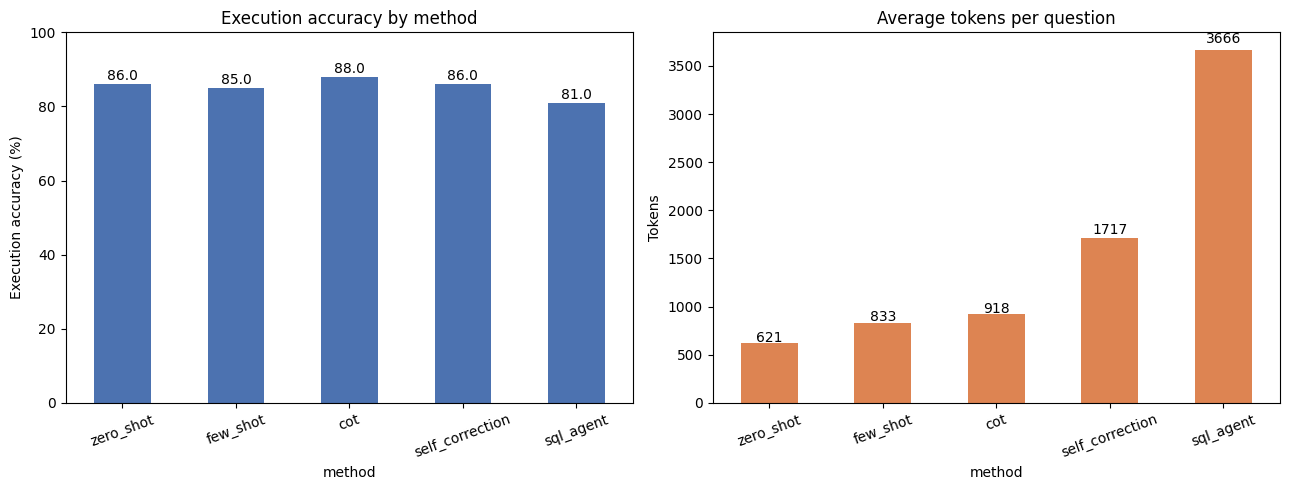

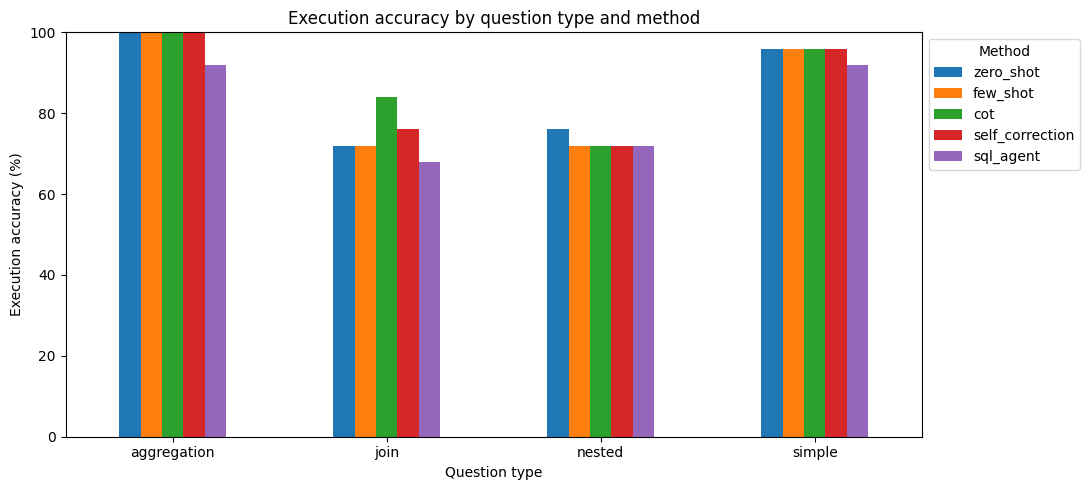

In [23]:
import matplotlib.pyplot as plt

gen = pd.read_csv('results_generation.csv')
sc = pd.read_csv('results_selfcorrect.csv')
ag = pd.read_csv('results_agent.csv')
print("Agent questions completed:", len(ag))

cot = gen[gen['style'] == 'cot'].set_index('qid')

frames = []
for style in ['zero_shot', 'few_shot', 'cot']:
    d = gen[gen['style'] == style]
    frames.append(pd.DataFrame({
        'method': style, 'qid': d['qid'], 'category': d['category'],
        'exec_match': d['exec_match'], 'exact_match': d['exact_match'],
        'tokens': d['tokens'], 'latency_s': d['latency_s'], 'corrections': 0,
    }))

frames.append(pd.DataFrame({
    'method': 'self_correction', 'qid': sc['qid'], 'category': sc['category'],
    'exec_match': sc['exec_match'], 'exact_match': sc['exact_match'],
    'tokens': sc['qid'].map(cot['tokens']) + sc['check_tokens'],
    'latency_s': sc['qid'].map(cot['latency_s']) + sc['latency_s'],
    'corrections': sc['corrections'],
}))

frames.append(pd.DataFrame({
    'method': 'sql_agent', 'qid': ag['qid'], 'category': ag['category'],
    'exec_match': ag['exec_match'], 'exact_match': ag['exact_match'],
    'tokens': ag['tokens'], 'latency_s': ag['latency_s'],
    'corrections': (ag['query_runs'] - 1).clip(lower=0),
}))

allm = pd.concat(frames, ignore_index=True)
order = ['zero_shot', 'few_shot', 'cot', 'self_correction', 'sql_agent']

final = allm.groupby('method').agg(
    questions=('qid', 'count'),
    execution_accuracy=('exec_match', 'mean'),
    exact_match_accuracy=('exact_match', 'mean'),
    avg_tokens=('tokens', 'mean'),
    avg_latency_s=('latency_s', 'mean'),
    avg_correction_iterations=('corrections', 'mean'),
).reindex(order)
final['execution_accuracy'] = (final['execution_accuracy'] * 100).round(1)
final['exact_match_accuracy'] = (final['exact_match_accuracy'] * 100).round(1)
final['avg_tokens'] = final['avg_tokens'].round(0)
final['avg_latency_s'] = final['avg_latency_s'].round(2)
final['avg_correction_iterations'] = final['avg_correction_iterations'].round(2)

print("FINAL COMPARISON OF ALL METHODS")
display(final)
final.to_csv('final_comparison.csv')

print("Agent runs that failed (loop limit or tool error):", ag['agent_error'].notna().sum())

by_type = (allm.pivot_table(index='category', columns='method',
                            values='exec_match', aggfunc='mean') * 100).round(1)[order]
print("EXECUTION ACCURACY BY QUESTION TYPE (%)")
display(by_type)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
final['execution_accuracy'].plot(kind='bar', ax=axes[0], color='#4C72B0')
axes[0].set_title('Execution accuracy by method')
axes[0].set_ylabel('Execution accuracy (%)')
axes[0].set_ylim(0, 100)
axes[0].tick_params(axis='x', rotation=20)
for i, v in enumerate(final['execution_accuracy']):
    axes[0].text(i, v + 1, f"{v}", ha='center')

final['avg_tokens'].plot(kind='bar', ax=axes[1], color='#DD8452')
axes[1].set_title('Average tokens per question')
axes[1].set_ylabel('Tokens')
axes[1].tick_params(axis='x', rotation=20)
for i, v in enumerate(final['avg_tokens']):
    axes[1].text(i, v * 1.02, f"{int(v)}", ha='center')

plt.tight_layout()
plt.savefig('chart_final_comparison.png', dpi=150)
plt.show()

by_type.plot(kind='bar', figsize=(11, 5))
plt.title('Execution accuracy by question type and method')
plt.ylabel('Execution accuracy (%)')
plt.xlabel('Question type')
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title='Method', loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.savefig('chart_final_by_type.png', dpi=150)
plt.show()

## 12. Summary of findings
- **CoT with query planning** gives the highest execution accuracy (88%), driven by joins (84% vs 72% for zero/few-shot).
- **Aggregation** is solved by every prompting style (100%); **nested queries** stay hardest (72–76%) whatever the method.
- **Exact match is far below execution accuracy** (20–33%): the model writes correct SQL in its own style. Few-shot has the highest exact match because it copies Spider's patterns.
- **Self-correction with the same model** fixed no answers, changed 2 debatable ones and roughly doubled the cost (0.05 correction iterations): almost no queries crash, and the reviewer shares the generator's blind spots.
- **The SQL agent** costs ~4× the tokens and ~3.4× the time of CoT and scored lower. It sees only the tables it chooses to inspect and occasionally loops, although it does use real execution feedback more often (0.25 correction iterations).
- Several remaining "errors" are Spider label issues or ambiguous questions (see Section 7).

## Utilities: backup and restore
Colab deletes files when the session ends. Run the **backup** cell after a run; after reconnecting, run the **restore** cell first, then *Runtime → Run before* on the pilot cell in Section 4. The cleanup cell removes agent rows that failed for technical reasons so they can be re-run.

In [24]:
from google.colab import drive
drive.mount('/content/drive')

!mkdir -p /content/drive/MyDrive/NL2SQL
!cp test_set_100.csv results_generation.csv results_selfcorrect.csv results_agent.csv /content/drive/MyDrive/NL2SQL/
!cp final_comparison.csv chart_generation_by_type.png chart_final_comparison.png chart_final_by_type.png /content/drive/MyDrive/NL2SQL/
!ls /content/drive/MyDrive/NL2SQL

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
cp: cannot stat 'chart_generation_by_type.png': No such file or directory
chart_final_by_type.png       final_comparison.csv    results_selfcorrect.csv
chart_final_comparison.png    results_agent.csv       test_set_100.csv
chart_generation_by_type.png  results_generation.csv


In [20]:
from google.colab import drive
drive.mount('/content/drive')

!cp /content/drive/MyDrive/NL2SQL/*.csv .
!ls

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
drive		      results_generation.csv   spider_data.zip
final_comparison.csv  results_selfcorrect.csv  test_set_100.csv
__MACOSX	      sample_data
results_agent.csv     spider_data


In [18]:
AGENT_FILE = 'results_agent.csv'
ag = pd.read_csv(AGENT_FILE)
bad = ag['agent_error'].fillna('').str.contains('fromisoformat|rate-limit')
print("Removing", bad.sum(), "rows to re-run:", list(ag.loc[bad, 'qid']))
ag[~bad].to_csv(AGENT_FILE, index=False)

Removing 0 rows to re-run: []
